#Python Data Cleaning and Visualization
Date: November 8, 2026
StudentID: tsegeb0956

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#Load the Airbnb dataset
df = pd.read_excel("AirBnBSummary_v2.xlsx")
#Display the first five rows
display(df.head())
#Check dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())

,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
0,7909479,41706311,David,Downtown,Entire home/apt,107.0,30,27,365.0,NaN
1,15966488,103700433,Erin,Downtown,Entire home/apt,100.0,1,250,74.0,NaN
2,19859814,103700433,Erin,Downtown,Entire home/apt,100.0,1,309,79.0,NaN
3,21071138,22992627,Joseph,Downtown,Entire home/apt,100.0,2,144,338.0,NaN
4,21712505,103700433,Erin,Downtown,Entire home/apt,100.0,1,178,68.0,NaN


Dataset loaded successfully!
Dataset shape: (1779, 10)
Column names:
['id', 'host_id', 'host_name', 'neighbourhood', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'availability_365', '<StudentID>']


Original dataset: (1779, 10)


C:\Users\Student\AppData\Local\Temp\ipykernel_1236\3300354359.py:33: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object").columns


DATA CLEANING COMPLETED
Remaining listings: 1239
Duplicates remaining: 0
Missing values remaining: 0
DESCRIPTIVE STATISTICS
Total listings: 1239
Minimum price: 32.0
Maximum price: 308.0
Mean price: 132.43
Median reviews: 21.0
Mode minimum nights: [1]
Standard deviation of price: 62.41
Price and availability correlation: 0.098


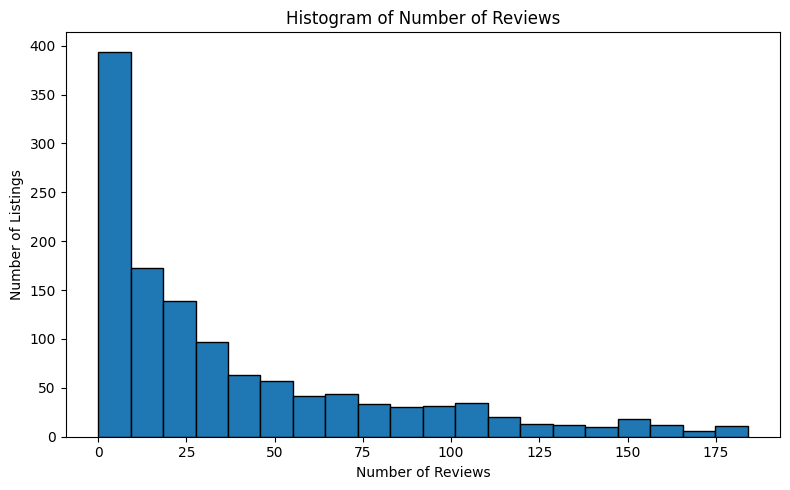

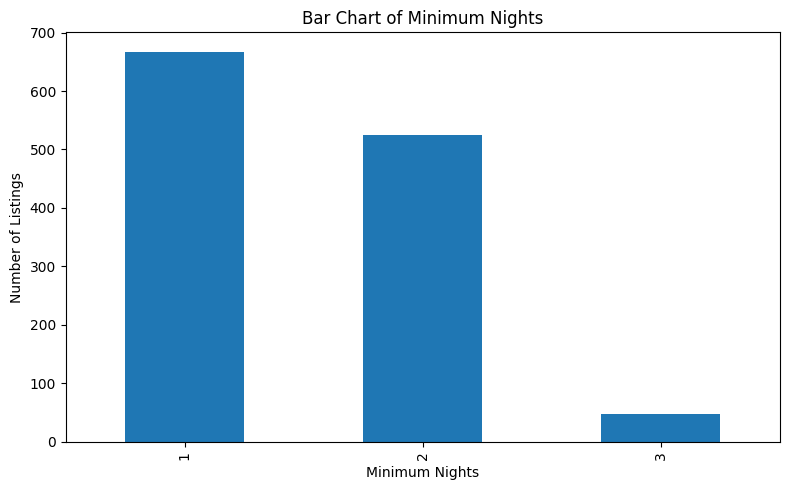

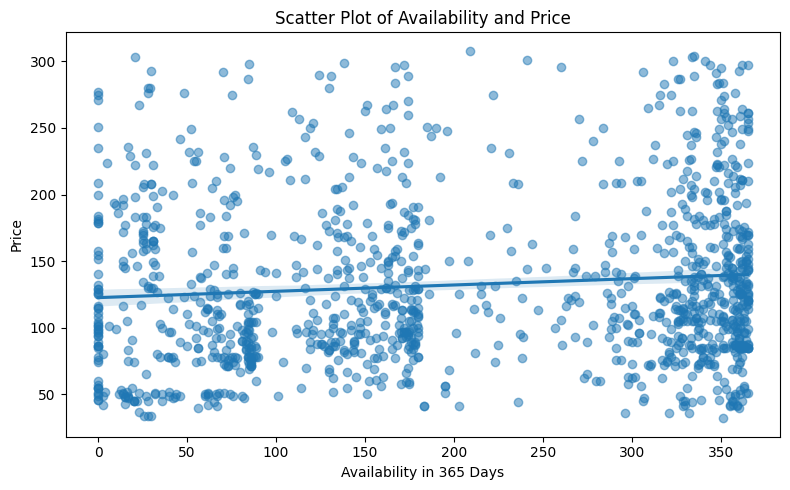

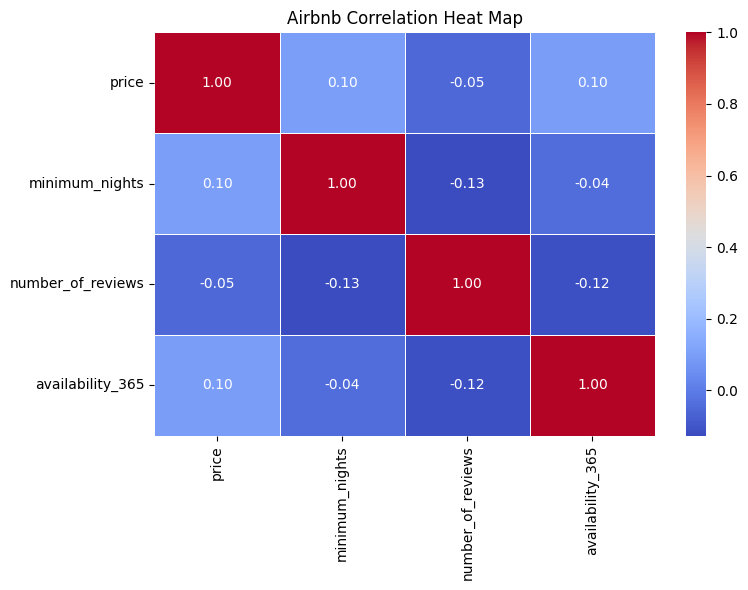

ALL TASKS COMPLETED SUCCESSFULLY
Cleaned Excel file: AirBnBSummary_v2_Python_Cleaned.xlsx


In [16]:

# AIRBNB 2022 - DATA CLEANING AND VISUALIZATION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD DATASET
df = pd.read_excel("AirBnBSummary_v2.xlsx")

print("Original dataset:", df.shape)

# 2. REMOVE EMPTY COLUMNS
df = df.dropna(axis=1, how="all")

# 3. REMOVE DUPLICATES
df = df.drop_duplicates()

# 4. FIX CAPITALIZATION
df["room_type"] = df["room_type"].replace(
    "Private room", "Private Room"
)

# 5. FILL MISSING VALUES USING MEDIAN
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    median_value = df[col].median()
    if pd.notna(median_value):
        df[col] = df[col].fillna(median_value)

# Fill missing text values using the mode
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    if df[col].isna().any():
        if not df[col].mode().empty:
            df[col] = df[col].fillna(df[col].mode()[0])

# 6. REMOVE OUTLIERS USING IQR
outlier_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "availability_365"
]

for col in outlier_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    df = df[
        (df[col] >= lower) & (df[col] <= upper)
    ].copy()

# 7. SAVE CLEANED EXCEL FILE
df.to_excel("AirBnBSummary_v2_Python_Cleaned.xlsx", index=False)

print("DATA CLEANING COMPLETED")
print("Remaining listings:", len(df))
print("Duplicates remaining:", df.duplicated().sum())
print("Missing values remaining:", df.isna().sum().sum())

# 8. DESCRIPTIVE STATISTICS
print("DESCRIPTIVE STATISTICS")

print("Total listings:", df.shape[0])
print("Minimum price:", df["price"].min())
print("Maximum price:", df["price"].max())
print("Mean price:", round(df["price"].mean(), 2))
print("Median reviews:", df["number_of_reviews"].median())
print("Mode minimum nights:", df["minimum_nights"].mode().tolist())
print("Standard deviation of price:", round(df["price"].std(), 2))
print("Price and availability correlation:",
      round(df["price"].corr(df["availability_365"]), 3))

# 9. HISTOGRAM
plt.figure(figsize=(8, 5))
plt.hist(df["number_of_reviews"], bins=20, edgecolor="black")
plt.title("Histogram of Number of Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

# 10. BAR CHART
plt.figure(figsize=(8, 5))
df["minimum_nights"].value_counts().head(15).sort_index().plot(kind="bar")
plt.title("Bar Chart of Minimum Nights")
plt.xlabel("Minimum Nights")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

# 11. SCATTER PLOT WITH TREND LINE
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df,
    x="availability_365",
    y="price",
    scatter_kws={"alpha": 0.5}
)
plt.title("Scatter Plot of Availability and Price")
plt.xlabel("Availability in 365 Days")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

# 12. CORRELATION HEAT MAP
columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "availability_365"
]

corr = df[columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Airbnb Correlation Heat Map")
plt.tight_layout()
plt.show()

print("ALL TASKS COMPLETED SUCCESSFULLY")
print("Cleaned Excel file: AirBnBSummary_v2_Python_Cleaned.xlsx")
